In [4]:
pip install scikit-learn

   ---------------------------------------- 0.0/8.4 MB ? eta -:--:--
   - -------------------------------------- 0.3/8.4 MB ? eta -:--:--
   ----- ---------------------------------- 1.0/8.4 MB 3.3 MB/s eta 0:00:03
   ------ --------------------------------- 1.3/8.4 MB 2.3 MB/s eta 0:00:04
   -------- ------------------------------- 1.8/8.4 MB 2.5 MB/s eta 0:00:03
   ------------ --------------------------- 2.6/8.4 MB 2.7 MB/s eta 0:00:03
   --------------- ------------------------ 3.1/8.4 MB 2.7 MB/s eta 0:00:02
   ------------------ --------------------- 3.9/8.4 MB 2.8 MB/s eta 0:00:02
   --------------------- ------------------ 4.5/8.4 MB 2.9 MB/s eta 0:00:02
   ------------------------- -------------- 5.2/8.4 MB 2.9 MB/s eta 0:00:02
   ---------------------------- ----------- 6.0/8.4 MB 3.1 MB/s eta 0:00:01
   -------------------------------- ------- 6.8/8.4 MB 3.1 MB/s eta 0:00:01
   ------------------------------------ --- 7.6/8.4 MB 3.2 MB/s eta 0:00:01
   -----------------------

In [15]:
import pandas as pd
import numpy as np
import seaborn as sns
from sklearn.preprocessing import StandardScaler,LabelEncoder,OneHotEncoder,OrdinalEncoder
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import FunctionTransformer
import pickle
import warnings
warnings.filterwarnings("ignore")

In [16]:
df=pd.read_csv("loan_approved.csv")

In [17]:
df.head()

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status (Approved)
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


In [18]:
df.isnull().sum()

Loan_ID                    0
Gender                    13
Married                    3
Dependents                15
Education                  0
Self_Employed             32
ApplicantIncome            0
CoapplicantIncome          0
LoanAmount                22
Loan_Amount_Term          14
Credit_History            50
Property_Area              0
Loan_Status (Approved)     0
dtype: int64

## imputing the null values

In [19]:
df['Gender'].value_counts()

Gender
Male      489
Female    112
Name: count, dtype: int64

In [20]:
df.loc[df['Gender'].isnull(),'Gender']="Male"

In [21]:
df.Gender.isnull().sum()

np.int64(0)

In [22]:
df.loc[df['Credit_History'].isnull(),'Credit_History']=0.0

In [23]:
df.Credit_History.isnull().sum()

np.int64(0)

In [24]:
df.loc[df['LoanAmount'].isnull(),'LoanAmount']=df['LoanAmount'].median()

In [25]:
df.LoanAmount.isnull().sum()

np.int64(0)

In [26]:
df['Education'].value_counts()

Education
Graduate        480
Not Graduate    134
Name: count, dtype: int64

In [27]:
df.loc[df['Education'].isnull(),'Education']="Graduate"

In [28]:
df.Education.isnull().sum()

np.int64(0)

In [29]:
df['Married'].value_counts()

Married
Yes    398
No     213
Name: count, dtype: int64

In [30]:
df.loc[df['Married'].isnull(),'Married']="Yes"

In [31]:
df.Married.isnull().sum()

np.int64(0)

In [32]:
df['Self_Employed'].value_counts()

Self_Employed
No     500
Yes     82
Name: count, dtype: int64

In [33]:
df.loc[df['Self_Employed'].isnull(),'Self_Employed']="No"

In [34]:
df.Self_Employed.isnull().sum()

np.int64(0)

In [35]:
df['Loan_Amount_Term'].value_counts() 

Loan_Amount_Term
360.0    512
180.0     44
480.0     15
300.0     13
240.0      4
84.0       4
120.0      3
60.0       2
36.0       2
12.0       1
Name: count, dtype: int64

In [36]:
df.loc[df['Loan_Amount_Term'].isnull(),'Loan_Amount_Term']=360.0

In [37]:
df.Loan_Amount_Term.isnull().sum()

np.int64(0)

In [38]:
df['Dependents'].value_counts()

Dependents
0     345
1     102
2     101
3+     51
Name: count, dtype: int64

In [39]:
df.loc[df['Dependents'].isnull(),'Dependents']="0"

In [40]:
df.isnull().sum()

Loan_ID                   0
Gender                    0
Married                   0
Dependents                0
Education                 0
Self_Employed             0
ApplicantIncome           0
CoapplicantIncome         0
LoanAmount                0
Loan_Amount_Term          0
Credit_History            0
Property_Area             0
Loan_Status (Approved)    0
dtype: int64

## Visualization of outliers

<Axes: xlabel='LoanAmount'>

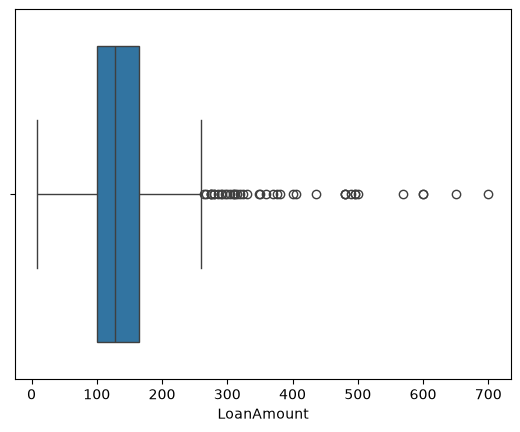

In [41]:
sns.boxplot(x=df.LoanAmount , orient='h')

## using Winsorize Method to Handle Outliers

<Axes: xlabel='ApplicantIncome'>

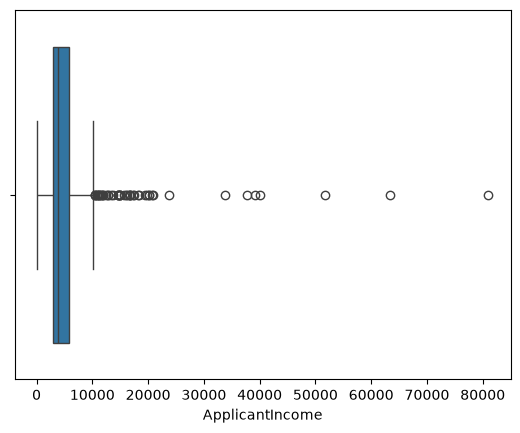

In [42]:
sns.boxplot(x=df.ApplicantIncome,orient='h')

In [43]:
from scipy.stats.mstats import winsorize

# Speciify the percentage of data to be trimmed from both ends
trim_percentage=0.08
#winsorize the specific columns
df['ApplicantIncome']=winsorize(df['ApplicantIncome'],limits=trim_percentage)

<Axes: xlabel='ApplicantIncome'>

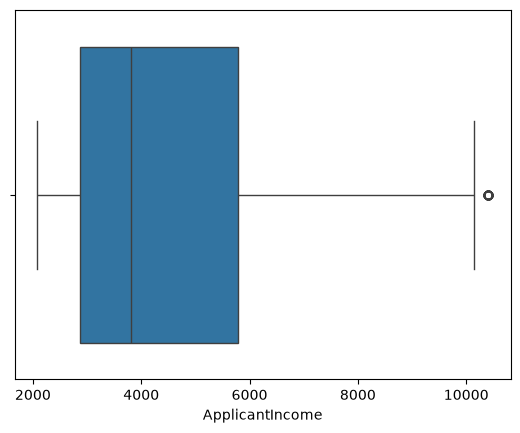

In [44]:
sns.boxplot(x=df['ApplicantIncome'],orient='h')

## Using IQR method to handle outliers

In [45]:
Q1= df['LoanAmount'].quantile(0.25)
Q3= df['LoanAmount'].quantile(0.75)

In [46]:
#calacutating IQR
IQR= Q3 - Q1
IQR

np.float64(64.5)

In [47]:
#define lower bound n upper bound
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

In [48]:
print(lower_bound)
print(upper_bound)

3.5
261.5


### Removing Outliers

In [49]:
df = df[(df['LoanAmount']>= lower_bound) & (df['LoanAmount']<= upper_bound)]

<Axes: xlabel='LoanAmount'>

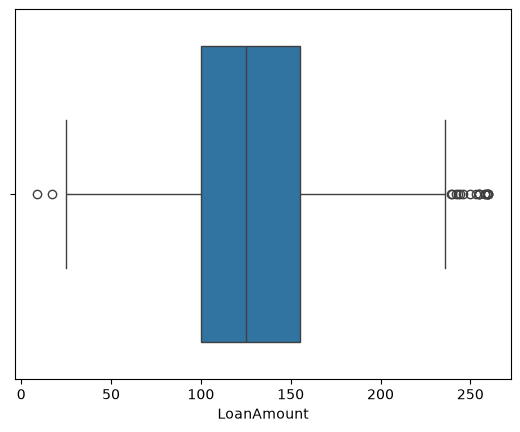

In [50]:
sns.boxplot(x=df.LoanAmount, orient='h')

# Encoding(catagorical to numerical)

## ONE HOT encoder(it represent each catagory as binary vector)

In [51]:
df_encoded = pd.get_dummies(df, columns=['Married'],prefix='Married')

In [52]:
df_encoded.columns

Index(['Loan_ID', 'Gender', 'Dependents', 'Education', 'Self_Employed',
       'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount',
       'Loan_Amount_Term', 'Credit_History', 'Property_Area',
       'Loan_Status (Approved)', 'Married_No', 'Married_Yes'],
      dtype='str')

## Label encoder(based on alphabitical order)

In [53]:
encoder = LabelEncoder()

# fit and transform the 'matchtype' column to obtain label-encoded values
df['Married'] = encoder.fit_transform(df['Married'])
# display
print(df[["Married"]])

     Married
0          0
1          1
2          1
3          1
4          0
..       ...
609        0
610        1
611        1
612        1
613        0

[573 rows x 1 columns]


In [54]:
df["Loan_Status (Approved)"]=encoder.fit_transform(df['Loan_Status (Approved)'])
print(df[['Loan_Status (Approved)']])

     Loan_Status (Approved)
0                         1
1                         0
2                         1
3                         1
4                         1
..                      ...
609                       1
610                       1
611                       1
612                       1
613                       0

[573 rows x 1 columns]


## ordinal encoder(based on customization)

In [55]:
df.Education.value_counts()

Education
Graduate        440
Not Graduate    133
Name: count, dtype: int64

In [56]:
Education_enc=OrdinalEncoder(categories=[['Graduate','not Graduate']])

In [57]:
df['Education'] = encoder.fit_transform(df[['Education']]) 

In [58]:
df.Education.value_counts()

Education
0    440
1    133
Name: count, dtype: int64

  ## implementation

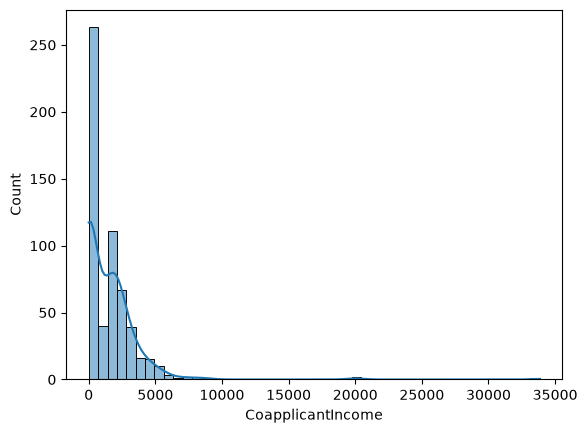

In [59]:
sns.histplot(x=df['CoapplicantIncome'], kde=True)
plt.show()

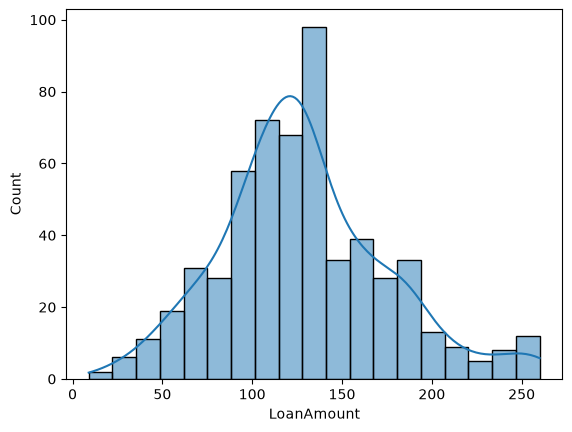

In [60]:
sns.histplot(x=df['LoanAmount'], kde=True)
plt.show()

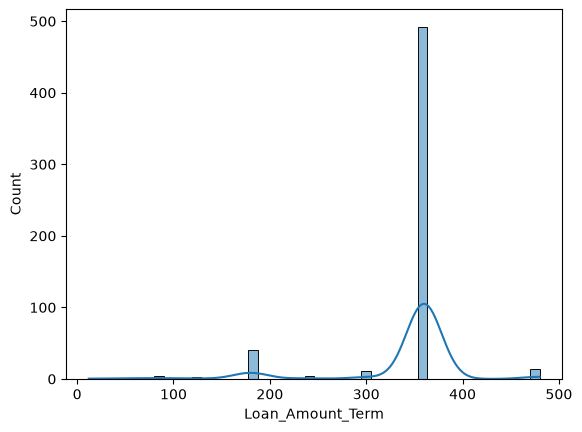

In [61]:
sns.histplot(x=df['Loan_Amount_Term'], kde=True)
plt.show()

### using log Transfromation

In [62]:
df['CoapplicantIncome']=np.log(df['CoapplicantIncome'])

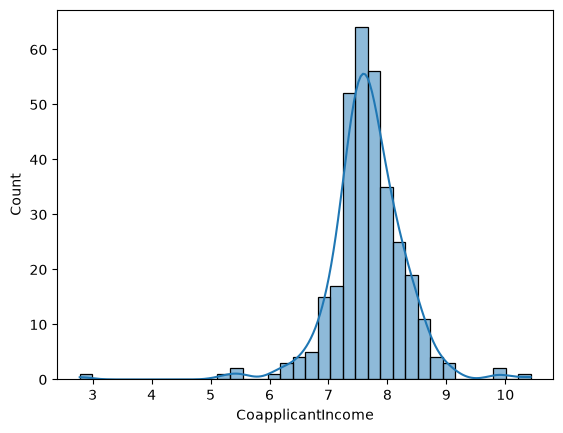

In [63]:
sns.histplot(x=df['CoapplicantIncome'], kde=True)
plt.show()

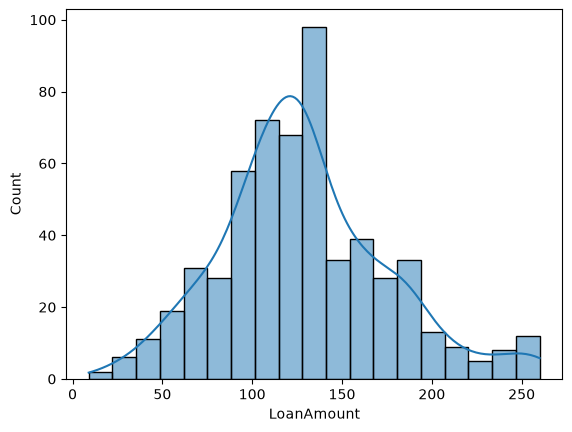

In [64]:
sns.histplot(x=df['LoanAmount'], kde=True)
plt.show()

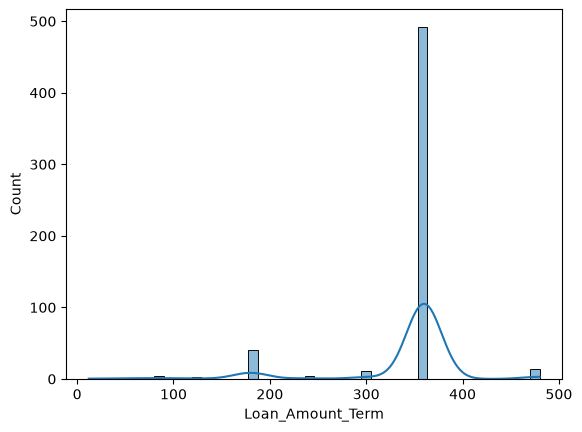

In [65]:
sns.histplot(x=df['Loan_Amount_Term'], kde=True)
plt.show()

### using Exponential transfromation

In [66]:
df['ApplicantIncome_exponential']=df.ApplicantIncome**(1/1.2)

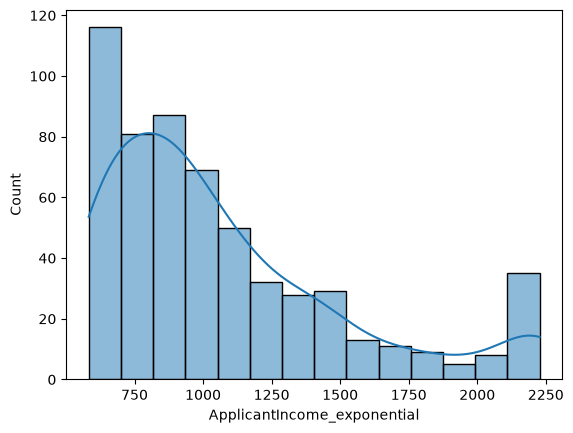

In [67]:
sns.histplot(x=df['ApplicantIncome_exponential'], kde=True)
plt.show()

### using squareroot Transfromation

In [68]:
df['LoanAmount']=df.LoanAmount**(1/2)

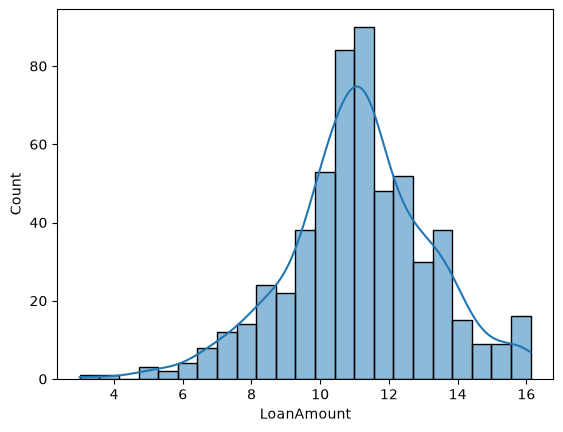

In [69]:
sns.histplot(x=df['LoanAmount'], kde=True)
plt.show()

In [70]:
df['Loan_Amount_Term']=df.Loan_Amount_Term**(1/2)

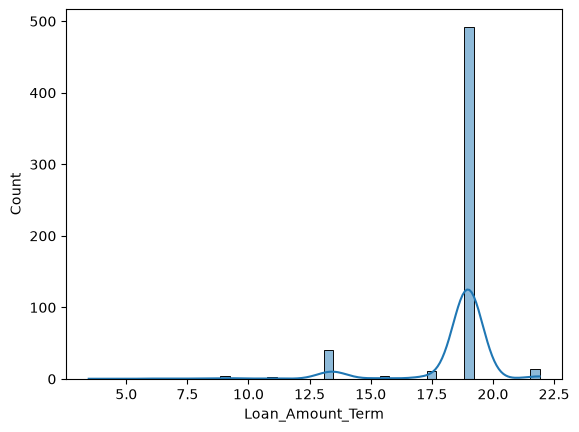

In [71]:
sns.histplot(x=df['Loan_Amount_Term'], kde=True)
plt.show()

## using box cox Transfromation

In [72]:
from scipy.stats import boxcox
transformed_data,lambda_value=boxcox(df['Loan_Amount_Term'])

In [73]:
#print('Transformed data:, transfromed_data')

In [74]:
print("Lambda value:", lambda_value)

Lambda value: 6.037107836493116


# Scaling

# using stander scalar(-3to+3)

In [75]:
df.columns

Index(['Loan_ID', 'Gender', 'Married', 'Dependents', 'Education',
       'Self_Employed', 'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount',
       'Loan_Amount_Term', 'Credit_History', 'Property_Area',
       'Loan_Status (Approved)', 'ApplicantIncome_exponential'],
      dtype='str')

In [76]:
scaler = StandardScaler()

In [77]:
ApplicantIncome_scaled= scaler.fit_transform(df[['ApplicantIncome']])

In [80]:
#ApplicantIncome_scaled

# Using min-max Scaler(0 to 1)

In [83]:
from sklearn.preprocessing import MinMaxScaler

In [84]:
scaler = MinMaxScaler()
ApplicantIncome_scaled2 = scaler.fit_transform(df[['ApplicantIncome']])

In [ ]:
#ApplicantIncome_scaled2

# Using Robust Scaler(-1 to +1)

In [85]:
from sklearn.preprocessing import RobustScaler

In [86]:
scaler = RobustScaler()
ApplicantIncome_scaled3 = scaler.fit_transform(df[['ApplicantIncome']])

In [ ]:
#ApplicantIncome_scaled3